In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un becario ha transcrito el cuadro de prelaciones de un proyecto tal como se adjunta: con mayúsculas y minúsculas mezcladas, separadores distintos, espacios de más, alguna predecesora repetida y varias formas de decir «ninguna».

In [4]:
pregunta_1 = "1. Enumere los defectos de la tabla que impedirían leerla directamente con la librería.  "
pregunta_2 = "2. Normalice la tabla con código (una regla para cada defecto) hasta obtener un cuadro de prelaciones válido: nombres en mayúscula, predecesoras separadas por comas y `---` para las actividades iniciales.  "
pregunta_3 = "3. Construya el proyecto, indique las actividades iniciales y finales y compruebe que no hay prelaciones redundantes ni ciclos.  "
pregunta_4 = "4. Dibuje el grafo PERT.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Enumere los defectos de la tabla que impedirían leerla directamente con la librería.  

2. Normalice la tabla con código (una regla para cada defecto) hasta obtener un cuadro de prelaciones válido: nombres en mayúscula, predecesoras separadas por comas y `---` para las actividades iniciales.  

3. Construya el proyecto, indique las actividades iniciales y finales y compruebe que no hay prelaciones redundantes ni ciclos.  

4. Dibuje el grafo PERT.  

In [5]:
#| tbl-cap: "Tabla recibida"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  actividad, predecesoras  
    ('A'      , 'ninguna'     ),
    ('B'      , 'ninguna'     ),
    ('C'      , '---'         ),
    ('D'      , 'B'           ),
    ('E'      , 'C'           ),
    ('F'      , 'b  / e  / b '),
    ('g'      , 'A,D ,F,a '   ),
    ('h'      , 'e,E '        ),
    ('I'      , 'g; H'        ),
], columns=['actividad', 'predecesoras']).set_index('actividad')
datos_enunciado

,predecesoras
actividad,
A,ninguna
B,ninguna
C,---
D,B
E,C
F,b / e / b
g,"A,D ,F,a"
h,"e,E"
I,g; H


# Resolución

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Enumere los defectos de la tabla que impedirían leerla directamente con la librería.  

In [7]:
defectos = []
t = datos_enunciado.reset_index()
if (t['actividad'] != t['actividad'].str.upper()).any(): defectos.append('nombres de actividad en minúscula')
if t['predecesoras'].str.contains(r'[a-z]').any(): defectos.append('predecesoras en minúscula')
if t['predecesoras'].str.contains(r';| y | /').any(): defectos.append('separadores distintos de la coma (;, y, /)')
if (t['predecesoras'] != t['predecesoras'].str.strip()).any() or t['predecesoras'].str.contains(r'\s,|,\s\s').any(): defectos.append('espacios sobrantes')
if t['predecesoras'].str.lower().isin(['ninguna', '-', '']).any(): defectos.append('varias formas de indicar que no hay predecesoras')
import re
def _partes(s):
    return [p.strip().upper() for p in re.split(r'[,;/]| y ', s) if p.strip()]
if any(len(_partes(s)) != len(set(_partes(s))) for s in t['predecesoras']): defectos.append('predecesoras repetidas')
for d in defectos:
    print('-', d)

- nombres de actividad en minúscula
- predecesoras en minúscula
- separadores distintos de la coma (;, y, /)
- espacios sobrantes
- varias formas de indicar que no hay predecesoras
- predecesoras repetidas


## Apartado 2

In [8]:
display(Markdown(pregunta_2))

2. Normalice la tabla con código (una regla para cada defecto) hasta obtener un cuadro de prelaciones válido: nombres en mayúscula, predecesoras separadas por comas y `---` para las actividades iniciales.  

Cada regla corrige un defecto: pasar a mayúsculas, trocear por cualquiera de los separadores, quitar espacios, eliminar repetidos (conservando el orden) y traducir las formas de «ninguna» a `---`.

In [9]:
def normaliza(s):
    s = str(s).strip()
    if s.lower() in ('', '-', '---', 'ninguna'):
        return '---'
    vistas = []
    for p in _partes(s):
        if p not in vistas:
            vistas.append(p)
    return ','.join(vistas)
limpio = pd.DataFrame({'activity': t['actividad'].str.strip().str.upper(),
                       'predecessor': t['predecesoras'].map(normaliza)}).set_index('activity')
pd.concat({'recibido': t.set_index(limpio.index)['predecesoras'], 'normalizado': limpio['predecessor']}, axis=1)

,recibido,normalizado
activity,,
A,ninguna,---
B,ninguna,---
C,---,---
D,B,B
E,C,C
F,b / e / b,"B,E"
G,"A,D ,F,a","A,D,F"
H,"e,E",E
I,g; H,"G,H"


In [10]:
desconocidas = {p for s in limpio['predecessor'] if s != '---' for p in s.split(',')} - set(limpio.index)
print('Predecesoras que no son actividades de la tabla:', desconocidas or 'ninguna')

Predecesoras que no son actividades de la tabla: ninguna


## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Construya el proyecto, indique las actividades iniciales y finales y compruebe que no hay prelaciones redundantes ni ciclos.  

In [12]:
datos_proyecto = limpio.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
print('Actividades iniciales:', ', '.join(sorted(prelaciones.start_activities)))
print('Actividades finales:  ', ', '.join(sorted(prelaciones.end_activities)))

Actividades iniciales: A, B, C
Actividades finales:   I


In [13]:
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps])
G.add_nodes_from(datos_proyecto.index)
print('¿Hay ciclos?', not nx.is_directed_acyclic_graph(G))
redundantes = sorted(set(G.edges) - set(nx.transitive_reduction(G).edges))
print('Prelaciones redundantes:', redundantes or 'ninguna')

¿Hay ciclos? False
Prelaciones redundantes: ninguna


## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. Dibuje el grafo PERT.  

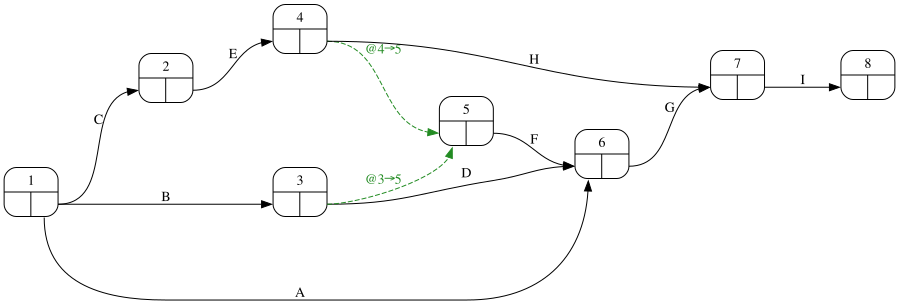

In [15]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)